# M6 — Monthly Median Composites with QA

This notebook orchestrates the full retrieval pipeline for the Wadi Gaza study.
For each **site** and each monthly **window** it builds a cloud-masked **median
composite** (reflectance bands + vegetation indices) and records the **QA
metrics** the PI asked to track.

**Per composite it produces:**
- a median composite of the requested bands + indices (`reduce="median"`), with
  clouds/shadows dropped per pixel via the **SCL** mask *before* the median;
- a QA row: number of scenes used, mean scene cloud %, % no-data pixels, and the
  mean per-pixel temporal standard deviation (a composite-stability measure).

**Approach decided with the PI:**
- Values come back as **surface reflectance in 0–1** — Sentinel Hub already
  applies the ÷10,000 scaling, so no manual rescaling is needed.
- Indices are computed **per scene, then medianed per pixel** (median-of-indices).
- SCL masking (PI guidance): **keep only** classes 4 (vegetation), 5 (bare soil),
  and 6 (water); drop everything else (0, 1, 2, 3, 7, 8, 9, 10, 11). Class 2
  (topographic shadow) is dropped because on this flat terrain it is most likely
  cloud shadow — revisit if it causes large recurring gaps.
- SAVI uses L = 0.428 with the standard ×(1+L) form.

Run the cells top to bottom.


In [1]:
import sys, os
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from rasterio.transform import from_bounds
from rasterio.features import geometry_mask

# Make the s2grab package importable whether we run from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "s2grab").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from s2grab import S2Client, aoi_from_bounds, make_evalscript, month_windows
from s2grab.sites import load_aois

client = S2Client()
print("s2grab ready. repo root:", ROOT)

s2grab ready. repo root: /home/tshihadah/code/wadi-gaza-research


/home/tshihadah/code/wadi-gaza-research/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 · Parameters

Everything you'd normally change lives here.

`DEMO = True` runs the real pipeline against the site polygons but trims the job
to a single window — **May of the most recent study year** — so you can validate
the full process quickly. Flip it to `False` to run every month/year window.

In [2]:
# --- What to run -------------------------------------------------------------
DEMO = False   # True: tiny fast validation run; False: full study configuration

# --- Sites (used when DEMO is False) -----------------------------------------
SITES_SOURCE = ROOT / "sites" / "StudySites.gpkg"
ID_FIELD = "site_name"      # attribute used to name each site
CLIP_TO_POLYGON = True      # mask output to each site's polygon

# --- Temporal windows --------------------------------------------------------
MONTHS = [1, 5, 9, 11]                 # Jan, May, Sep, Nov
YEARS = list(range(2019, 2026))        # 2019–2025

# --- Product -----------------------------------------------------------------
BANDS = ["B02", "B03", "B04", "B05", "B08", "B8A", "B11", "B12"]
INDICES = ["NDVI", "GNDVI", "SAVI", "NDRE"]
RESOLUTION = 10             # metres (common output grid for all bands)
UPSAMPLING = "NEAREST"      # how 20 m bands (B05, B8A, B11, B12) & NDRE are
                            # resampled onto the 10 m grid: "NEAREST" keeps exact
                            # values (blocky); "BILINEAR" is smoother but interpolates

# --- Filtering / masking -----------------------------------------------------
MAX_CLOUD = 20              # scene-level cloud filter (%); PI prefers 5, up to 10
# Per-pixel SCL masking (PI guidance): keep ONLY vegetation (4), bare soil (5),
# and water (6); drop everything else. Class 2 = "topographic shadows", which on
# this flat terrain is most likely cloud shadow, so it is dropped too. If that
# causes large recurring no-data gaps, add 2 back
MASK_SCL = [0, 1, 2, 3, 7, 8, 9, 10, 11]

# --- QA / output -------------------------------------------------------------
COMPUTE_STD = True          # also fetch a std composite for the stability metric
OUT_DIR = ROOT / "outputs" / "composites"

# --- Demo overrides ----------------------------------------------------------
# Demo runs the real pipeline (site polygons, masking, QA) but trims the work to
# a single window: May of the most recent study year.
if DEMO:
    MONTHS = [5]
    YEARS = [max(YEARS)]
    OUT_DIR = ROOT / "outputs" / "_demo_composites"

print("DEMO:", DEMO)
print("windows:", [(y, m) for y in YEARS for m in MONTHS])
print("product bands:", BANDS, "+ indices:", INDICES)
print("upsampling:", UPSAMPLING)
print("mask SCL:", MASK_SCL)
print("output dir:", OUT_DIR)

DEMO: False
windows: [(2019, 1), (2019, 5), (2019, 9), (2019, 11), (2020, 1), (2020, 5), (2020, 9), (2020, 11), (2021, 1), (2021, 5), (2021, 9), (2021, 11), (2022, 1), (2022, 5), (2022, 9), (2022, 11), (2023, 1), (2023, 5), (2023, 9), (2023, 11), (2024, 1), (2024, 5), (2024, 9), (2024, 11), (2025, 1), (2025, 5), (2025, 9), (2025, 11)]
product bands: ['B02', 'B03', 'B04', 'B05', 'B08', 'B8A', 'B11', 'B12'] + indices: ['NDVI', 'GNDVI', 'SAVI', 'NDRE']
upsampling: NEAREST
mask SCL: [0, 1, 2, 3, 7, 8, 9, 10, 11]
output dir: /home/tshihadah/code/wadi-gaza-research/outputs/composites


## 2 · Load areas of interest

We load every site polygon from the study geopackage
(`sites/StudySites.gpkg`, keyed on `site_name`) via `load_aois`, which reprojects
each to its local UTM zone and (optionally) keeps the polygon for clipping.


In [3]:
from shapely.validation import make_valid

sites = gpd.read_file(SITES_SOURCE)

# Filter for NahalRubin for testing
sites = sites[sites[ID_FIELD] == "NahalRubin"]

# Repair any self-intersecting / invalid rings here
invalid = ~sites.geometry.is_valid
if invalid.any():
    print(f"Repairing {int(invalid.sum())} invalid geometr(ies):",
          list(sites.loc[invalid, ID_FIELD]))
    sites.loc[invalid, "geometry"] = sites.loc[invalid, "geometry"].apply(make_valid)

aois = load_aois(
    sites,
    id_field=ID_FIELD,
    resolution=RESOLUTION,
    clip=CLIP_TO_POLYGON,
)

print(f"{len(aois)} site(s) loaded")
for name, aoi in list(aois.items())[:5]:
    print(f"  {name}: {aoi}")


1 site(s) loaded
  NahalRubin: AOI(EPSG:32636, 193x102px, 10.0m, polygon)


## 3 · Build the monthly windows

Each (year, month) pair becomes a calendar-month date range
`(YYYY-MM-01, YYYY-MM-DD)`. Scenes inside that range that pass the cloud filter
feed the composite.

In [4]:
windows = month_windows(YEARS, MONTHS)
pd.DataFrame(windows)

,label,year,month,start,end
0,2019-01,2019,1,2019-01-01,2019-01-31
1,2019-05,2019,5,2019-05-01,2019-05-31
2,2019-09,2019,9,2019-09-01,2019-09-30
3,2019-11,2019,11,2019-11-01,2019-11-30
4,2020-01,2020,1,2020-01-01,2020-01-31
5,2020-05,2020,5,2020-05-01,2020-05-31
6,2020-09,2020,9,2020-09-01,2020-09-30
7,2020-11,2020,11,2020-11-01,2020-11-30
8,2021-01,2021,1,2021-01-01,2021-01-31
9,2021-05,2021,5,2021-05-01,2021-05-31


## 4 · QA helpers

Two small functions:

- `study_area_mask(aoi, shape)` — a boolean mask of pixels *inside the study
  area*. For a clipped (polygon) AOI it rasterizes the polygon so pixels outside
  it are excluded from the no-data denominator; for a plain bbox AOI every pixel
  counts.
- `composite_qa(...)` — searches, fetches the median composite (and optionally a
  std composite), then computes the QA metrics over the study-area pixels.

In [5]:
def study_area_mask(aoi, shape: tuple[int, int]) -> np.ndarray:
    """Boolean (H, W) mask: True for pixels inside the study area.

    Clipped AOIs -> the polygon footprint; bbox AOIs -> everything.
    """
    height, width = shape
    if not aoi.is_clipped:
        return np.ones((height, width), dtype=bool)
    transform = from_bounds(*aoi.bbox, width=width, height=height)
    # invert=True -> True inside the geometry.
    return geometry_mask(
        [aoi.geometry.geometry],
        out_shape=(height, width),
        transform=transform,
        invert=True,
    )


def composite_qa(client, aoi, start, end, *, bands, indices,
                 max_cloud, mask_scl, compute_std, upsampling=None):
    """Fetch a masked median composite + QA for one AOI/window.

    Returns (image, qa) where image is None when no data qualifies.
    """
    scenes = client.search(aoi, start, end, max_cloud=max_cloud)
    n_scenes = len(scenes)
    clouds = [s.cloud_cover for s in scenes if s.cloud_cover is not None]
    mean_cloud = float(np.mean(clouds)) if clouds else float("nan")

    qa = {"n_scenes": n_scenes, "mean_cloud": mean_cloud,
          "pct_nodata": float("nan"), "mean_pixel_std": float("nan")}

    if n_scenes == 0:
        return None, qa

    median_prod = make_evalscript(bands=bands, indices=indices,
                                  reduce="median", mask_scl=mask_scl)
    image = client.fetch(aoi, start=start, end=end,
                         product=median_prod, max_cloud=max_cloud,
                         upsampling=upsampling)
    if image is None:
        return None, qa

    arr = image.array                              # (H, W, nbands)
    mask = study_area_mask(aoi, arr.shape[:2])     # (H, W)
    study_px = int(mask.sum())

    # A pixel is "no data" when every band is NaN (no valid observation).
    nodata = np.all(np.isnan(arr), axis=2) & mask
    qa["pct_nodata"] = 100.0 * nodata.sum() / study_px if study_px else float("nan")

    if compute_std:
        std_prod = make_evalscript(bands=bands, indices=indices,
                                   reduce="std", mask_scl=mask_scl)
        std_img = client.fetch(aoi, start=start, end=end,
                               product=std_prod, max_cloud=max_cloud,
                               upsampling=upsampling)
        if std_img is not None:
            qa["mean_pixel_std"] = float(np.nanmean(std_img.array[mask]))

    return image, qa

## 5 · Run the pipeline

For every site × window: search, composite, compute QA, and save a GeoTIFF.
Results are collected into a **manifest**. Failures (no scenes / no data) are
recorded rather than raised, so one bad window doesn't stop the run.

In [6]:
EMPTY_QA = {"n_scenes": None, "mean_cloud": None,
            "pct_nodata": None, "mean_pixel_std": None}

records = []
for site, aoi in aois.items():
    for w in windows:
        try:
            image, qa = composite_qa(
                client, aoi, w["start"], w["end"],
                bands=BANDS, indices=INDICES,
                max_cloud=MAX_CLOUD, mask_scl=MASK_SCL, compute_std=COMPUTE_STD,
                upsampling=UPSAMPLING,
            )
        except Exception as exc:  # keep the run going; log the failure
            records.append({"site": site, "window": w["label"],
                            "status": f"error: {exc}", "path": None, **EMPTY_QA})
            print(f"{site} {w['label']}: ERROR {exc}")
            continue

        if image is None:
            records.append({"site": site, "window": w["label"],
                            "status": "no data", "path": None, **qa})
            print(f"{site} {w['label']}: no data ({qa['n_scenes']} scenes)")
            continue

        path = OUT_DIR / site / f"{site}_{w['label']}.tif"
        image.save(path)
        records.append({"site": site, "window": w["label"], "status": "ok",
                        "path": str(path.relative_to(ROOT)), **qa})
        print(f"{site} {w['label']}: {qa['n_scenes']} scenes, "
              f"{qa['pct_nodata']:.1f}% no-data -> {path.name}")

manifest = pd.DataFrame(records)
print(f"\n{len(manifest)} composite(s) attempted")

NahalRubin 2019-01: 4 scenes, 0.0% no-data -> NahalRubin_2019-01.tif
NahalRubin 2019-05: 5 scenes, 0.0% no-data -> NahalRubin_2019-05.tif
NahalRubin 2019-09: 4 scenes, 0.9% no-data -> NahalRubin_2019-09.tif
NahalRubin 2019-11: 5 scenes, 0.0% no-data -> NahalRubin_2019-11.tif
NahalRubin 2020-01: 3 scenes, 0.0% no-data -> NahalRubin_2020-01.tif
NahalRubin 2020-05: 4 scenes, 0.0% no-data -> NahalRubin_2020-05.tif
NahalRubin 2020-09: 6 scenes, 0.3% no-data -> NahalRubin_2020-09.tif
NahalRubin 2020-11: 2 scenes, 0.0% no-data -> NahalRubin_2020-11.tif
NahalRubin 2021-01: 1 scenes, 0.0% no-data -> NahalRubin_2021-01.tif
NahalRubin 2021-05: 6 scenes, 0.0% no-data -> NahalRubin_2021-05.tif
NahalRubin 2021-09: 4 scenes, 1.8% no-data -> NahalRubin_2021-09.tif
NahalRubin 2021-11: 3 scenes, 0.0% no-data -> NahalRubin_2021-11.tif
NahalRubin 2022-01: 3 scenes, 0.0% no-data -> NahalRubin_2022-01.tif
NahalRubin 2022-05: 5 scenes, 0.0% no-data -> NahalRubin_2022-05.tif
NahalRubin 2022-09: 6 scenes, 0.5%

## 6 · QA manifest

One row per composite, with the metrics the PI asked to track, saved as a CSV
alongside the rasters for the study record.

In [7]:
cols = ["site", "window", "status", "n_scenes", "mean_cloud",
        "pct_nodata", "mean_pixel_std", "path"]
manifest = manifest.reindex(columns=cols)

manifest_path = OUT_DIR / "qa_manifest.csv"
manifest_path.parent.mkdir(parents=True, exist_ok=True)
manifest.to_csv(manifest_path, index=False)
print("manifest ->", manifest_path.relative_to(ROOT))
manifest

manifest -> outputs/composites/qa_manifest.csv


,site,window,status,n_scenes,mean_cloud,pct_nodata,mean_pixel_std,path
0,NahalRubin,2019-01,ok,4,1.117500,0.000000,0.017445,outputs/composites/NahalRubin/NahalRubin_2019-...
1,NahalRubin,2019-05,ok,5,7.942000,0.000000,0.015000,outputs/composites/NahalRubin/NahalRubin_2019-...
2,NahalRubin,2019-09,ok,4,7.152500,0.852417,0.017385,outputs/composites/NahalRubin/NahalRubin_2019-...
3,NahalRubin,2019-11,ok,5,0.106000,0.000000,0.019466,outputs/composites/NahalRubin/NahalRubin_2019-...
4,NahalRubin,2020-01,ok,3,4.536667,0.000000,0.013020,outputs/composites/NahalRubin/NahalRubin_2020-...
5,NahalRubin,2020-05,ok,4,8.357500,0.000000,0.019365,outputs/composites/NahalRubin/NahalRubin_2020-...
6,NahalRubin,2020-09,ok,6,1.026667,0.254453,0.018106,outputs/composites/NahalRubin/NahalRubin_2020-...
7,NahalRubin,2020-11,ok,2,16.890000,0.000000,0.006556,outputs/composites/NahalRubin/NahalRubin_2020-...
8,NahalRubin,2021-01,ok,1,12.750000,0.000000,0.000000,outputs/composites/NahalRubin/NahalRubin_2021-...
9,NahalRubin,2021-05,ok,6,4.321667,0.000000,0.017038,outputs/composites/NahalRubin/NahalRubin_2021-...


## 7 · Preview a composite

Quick look at the first successful composite: a true-colour RGB (from the
B04/B03/B02 bands) next to the NDVI layer. No-data pixels appear blank.

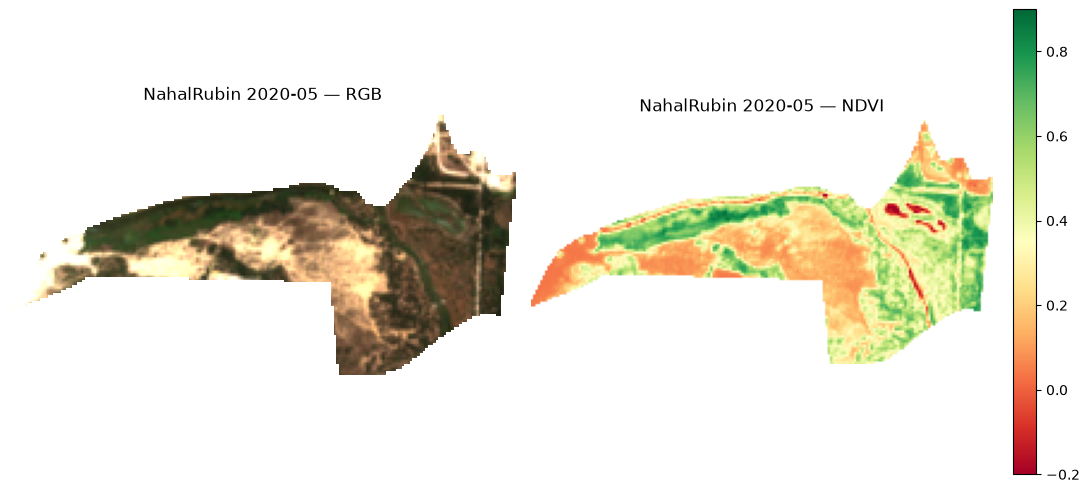

In [8]:
import rasterio

band_names = BANDS + INDICES
ok = manifest[manifest["status"] == "ok"]

if ok.empty:
    print("No successful composite to preview.")
else:
    row = ok.iloc[5]
    with rasterio.open(ROOT / row["path"]) as src:
        stack = np.transpose(src.read(), (1, 2, 0))  # (H, W, bands)

    def band(name):
        return stack[:, :, band_names.index(name)]

    rgb = np.clip(np.dstack([band("B04"), band("B03"), band("B02")]) / 0.3, 0, 1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    axes[0].imshow(rgb)
    axes[0].set_title(f"{row['site']} {row['window']} — RGB")
    im = axes[1].imshow(band("NDVI"), cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    axes[1].set_title(f"{row['site']} {row['window']} — NDVI")
    fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 8 · SCL class diagnostics (NahalRubin)

To tune the `MASK_SCL` set we fetch, for each NahalRubin window, a per-pixel
**count** of how many valid observations fall in each SCL class
(`make_scl_count_evalscript`, one `ORBIT` request per window). Because SCL classes
are mutually exclusive per scene, these counts are a *sufficient statistic*: a
pixel is no-data under a mask set $M$ exactly when
$\text{valid} - \sum_{c \in M}\text{count}_c = 0$. That lets us simulate any
candidate mask set offline — no refetching — identify which class is the *last
blocker* for the gap pixels, and see the class mix that drives the masking.

In [9]:
# --- Fetch per-pixel SCL class counts for NahalRubin (one ORBIT request/window)
# Returns a 13-band raster per window: ["valid", "SCL_0" ... "SCL_11"].
from s2grab import make_scl_count_evalscript

SITE = "NahalRubin"
site_aoi = aois[SITE]
scl_windows = month_windows(YEARS, MONTHS)

scl_product = make_scl_count_evalscript()
SCL_BANDS = list(scl_product.band_names)                       # 13 band names
band_idx = {int(n.split("_")[1]): i                            # SCL class -> band index
            for i, n in enumerate(SCL_BANDS) if n.startswith("SCL_")}

scl_counts = {}                                                # window label -> (H, W, 13)
for w in scl_windows:
    img = client.fetch(
        site_aoi, start=w["start"], end=w["end"],
        product=scl_product, max_cloud=MAX_CLOUD, upsampling=UPSAMPLING,
    )
    if img is None:
        print(f"{SITE} {w['label']}: no scenes")
        continue
    scl_counts[w["label"]] = img.array
    print(f"{SITE} {w['label']}: up to {int(img.array[:, :, 0].max())} valid obs/pixel")

print(f"\n{len(scl_counts)} window(s) fetched")

NahalRubin 2019-01: up to 4 valid obs/pixel
NahalRubin 2019-05: up to 5 valid obs/pixel
NahalRubin 2019-09: up to 4 valid obs/pixel
NahalRubin 2019-11: up to 5 valid obs/pixel
NahalRubin 2020-01: up to 3 valid obs/pixel
NahalRubin 2020-05: up to 4 valid obs/pixel
NahalRubin 2020-09: up to 6 valid obs/pixel
NahalRubin 2020-11: up to 2 valid obs/pixel
NahalRubin 2021-01: up to 1 valid obs/pixel
NahalRubin 2021-05: up to 6 valid obs/pixel
NahalRubin 2021-09: up to 4 valid obs/pixel
NahalRubin 2021-11: up to 3 valid obs/pixel
NahalRubin 2022-01: up to 3 valid obs/pixel
NahalRubin 2022-05: up to 5 valid obs/pixel
NahalRubin 2022-09: up to 6 valid obs/pixel
NahalRubin 2022-11: up to 2 valid obs/pixel
NahalRubin 2023-01: up to 2 valid obs/pixel
NahalRubin 2023-05: up to 5 valid obs/pixel
NahalRubin 2023-09: up to 6 valid obs/pixel
NahalRubin 2023-11: up to 4 valid obs/pixel
NahalRubin 2024-01: up to 1 valid obs/pixel
NahalRubin 2024-05: up to 4 valid obs/pixel
NahalRubin 2024-09: up to 3 vali

In [10]:
# --- Simulate candidate SCL mask sets offline (no refetching) ----------------
# Each candidate lists the classes to DROP. A pixel is no-data under a set when
# it has zero clear observations left: valid - sum(counts of masked classes) == 0.
mask_candidates = {
    "current":     set(MASK_SCL),                 # [0,1,2,3,7,8,9,10,11]
    "lib_default": {0, 1, 3, 8, 9, 10, 11},       # keeps 2 (dark) and 7 (unclassified)
    "keep_2":      set(MASK_SCL) - {2},           # stop dropping dark/topographic shadow
    "keep_2_7":    set(MASK_SCL) - {2, 7},
    "keep_2_3_7":  set(MASK_SCL) - {2, 3, 7},     # also keep cloud shadow
    "clouds_only": {0, 1, 8, 9, 10},              # only bad pixels + true clouds
}


def simulate_nodata(stack, mask_set, study):
    """% of study-area pixels with zero clear observations under mask_set."""
    valid = stack[:, :, 0]
    masked = sum((stack[:, :, band_idx[c]] for c in mask_set), np.zeros_like(valid))
    clear = valid - masked
    n = int(study.sum())
    return 100.0 * int(((clear <= 0) & study).sum()) / n if n else float("nan")


rows = []
for label, stack in scl_counts.items():
    study = study_area_mask(site_aoi, stack.shape[:2])
    rows.append({"window": label,
                 **{cand: simulate_nodata(stack, mset, study)
                    for cand, mset in mask_candidates.items()}})

sim = pd.DataFrame(rows).set_index("window").sort_index()
print("mean % no-data across windows, by candidate mask set:")
print(sim.mean().round(3).sort_values().to_string())
sim.round(3)

mean % no-data across windows, by candidate mask set:
lib_default    0.000
keep_2_7       0.000
clouds_only    0.000
keep_2_3_7     0.000
keep_2         0.304
current        0.304


,current,lib_default,keep_2,keep_2_7,keep_2_3_7,clouds_only
window,,,,,,
2019-01,0.000,0.0,0.000,0.0,0.0,0.0
2019-05,0.000,0.0,0.000,0.0,0.0,0.0
2019-09,0.852,0.0,0.852,0.0,0.0,0.0
2019-11,0.000,0.0,0.000,0.0,0.0,0.0
2020-01,0.000,0.0,0.000,0.0,0.0,0.0
2020-05,0.000,0.0,0.000,0.0,0.0,0.0
2020-09,0.254,0.0,0.254,0.0,0.0,0.0
2020-11,0.000,0.0,0.000,0.0,0.0,0.0
2021-01,0.000,0.0,0.000,0.0,0.0,0.0


In [11]:
# --- Validate: "current" simulation should reproduce the pipeline's pct_nodata
# (small diffs are expected from SCL 20 m -> 10 m resampling onto the output grid).
qa = pd.read_csv(OUT_DIR / "qa_manifest.csv")
qa = qa[qa["site"] == SITE].set_index("window")["pct_nodata"]
check = pd.DataFrame({"manifest": qa, "simulated_current": sim["current"]})
check["abs_diff"] = (check["manifest"] - check["simulated_current"]).abs()
check.round(3)

,manifest,simulated_current,abs_diff
window,,,
2019-01,0.000,0.000,0.0
2019-05,0.000,0.000,0.0
2019-09,0.852,0.852,0.0
2019-11,0.000,0.000,0.0
2020-01,0.000,0.000,0.0
2020-05,0.000,0.000,0.0
2020-09,0.254,0.254,0.0
2020-11,0.000,0.000,0.0
2021-01,0.000,0.000,0.0


In [12]:
# --- Observation-weighted SCL class mix per window --------------------------
# What % of ALL valid observations over the study area fell in each class.
# Shows which classes are prevalent (and thus candidates to stop masking).
mix_rows = []
for label, stack in scl_counts.items():
    study = study_area_mask(site_aoi, stack.shape[:2])
    total = float(stack[:, :, 0][study].sum())
    mix_rows.append({"window": label,
                     **{f"SCL_{c}": (100.0 * float(stack[:, :, i][study].sum()) / total
                                     if total else np.nan)
                        for c, i in band_idx.items()}})

mix = pd.DataFrame(mix_rows).set_index("window").sort_index()
mix = mix.loc[:, (mix.fillna(0) > 0).any()]   # drop classes that never appear
mix.round(3)

,SCL_2,SCL_3,SCL_4,SCL_5,SCL_6,SCL_7,SCL_8,SCL_9,SCL_10
window,,,,,,,,,
2019-01,0.000,0.000,45.579,54.408,0.013,0.000,0.000,0.000,0.000
2019-05,0.000,0.000,19.069,60.285,0.000,0.646,3.496,16.504,0.000
2019-09,0.000,0.000,18.556,79.205,0.000,2.239,0.000,0.000,0.000
2019-11,0.000,0.000,26.117,73.873,0.010,0.000,0.000,0.000,0.000
2020-01,0.000,0.000,44.805,55.161,0.034,0.000,0.000,0.000,0.000
2020-05,0.000,2.052,24.730,64.466,0.000,1.196,3.912,3.645,0.000
2020-09,0.000,2.752,11.751,82.981,0.000,2.515,0.000,0.000,0.000
2020-11,0.000,32.850,22.767,44.383,0.000,0.000,0.000,0.000,0.000
2021-01,0.000,0.000,42.087,57.913,0.000,0.000,0.000,0.000,0.000


## 9 · Notes & next steps

- **Scaling:** bands are surface reflectance (0–1); no ÷10,000 applied (Sentinel
  Hub already scales). SAVI uses L = 0.428 with the standard ×(1+L) form.
- **Cloud masking:** per PI guidance we **keep only** SCL 4 (vegetation),
  5 (bare soil), 6 (water) and drop all others (0, 1, 2, 3, 7, 8, 9, 10, 11)
  per pixel before the median. Class 2 (topographic shadow) is dropped as likely
  cloud shadow on this flat terrain; if it opens large recurring gaps, add 2 back
  to `SCL_KEEP`.
- **Resolution / resampling:** everything is delivered on a common **10 m** grid.
  The 10 m bands are B02, B03, B04, B08; the **20 m** bands (B05, B8A, B11, B12)
  and **NDRE** (built from B8A + B05) are **upsampled** from their native 20 m to
  10 m server-side — this aligns/stacks the layers (as the PI's land-cover step
  requires) but adds no real detail, so NDRE/SWIR carry 20 m information content.
  The resampling method is set explicitly via `UPSAMPLING` (default `"NEAREST"`,
  which preserves exact values; `"BILINEAR"` is smoother but interpolates).
- **QA captured:** scenes used, mean scene cloud %, % no-data (within the study
  polygon), and mean per-pixel temporal std (composite stability).
- **To scale up:** set `DEMO = False` to run the full site × window matrix. That
  is a large job (many sites × 24 windows × up to 2 requests each) — consider
  running a subset of sites first.
- **Possible additions:** persist per-band std rasters and the SCL layer for the
  record; polygon-level summary statistics (Statistical API); and, per the PI,
  computing NDVI-only for non–Wadi Gaza sites to save time.
